In [13]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import END, START
from langgraph.graph.state import StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage
import os
from dotenv import load_dotenv
load_dotenv()

True

In [14]:
os.environ["LANGSMITH_PROJECT"]=os.getenv("LANGCHAIN_PROJECT")

In [15]:
import os
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["LANGSMITH_API_KEY"]=os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGSMITH_TRACING"]="true"


In [16]:
from langchain.chat_models import init_chat_model
llm=init_chat_model("openai/gpt-oss-20b", model_provider="groq")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002579E89ED70>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002579E89F6F0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [17]:
class State(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [18]:
## Graph With tool Call
from langchain_core.tools import tool

@tool
def add(a:float,b:float):
    """Add two number"""
    return a+b
tools=[add]
tool_node=ToolNode([add])

llm_with_tool=llm.bind_tools([add])

def call_llm_model(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}


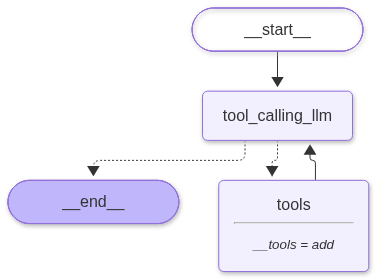

In [19]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def call_llm_model(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}
## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",call_llm_model)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
response=graph.invoke({"messages":"What is machine learning"})

In [21]:
response=graph.invoke({"messages":"What is machine learning"})

In [22]:
response

{'messages': [HumanMessage(content='What is machine learning', additional_kwargs={}, response_metadata={}, id='19a34b93-d420-45e8-9d6a-16aabb0fa1d6'),
  AIMessage(content='**Machine learning (ML)** is a subfield of artificial intelligence that focuses on building systems capable of learning from data, improving their performance over time without being explicitly programmed for each specific task.\n\n### Core Concepts\n\n| Concept | What it means |\n|---------|---------------|\n| **Data** | The raw information (images, text, numbers, etc.) the system uses to learn. |\n| **Model** | A mathematical representation (e.g., a neural network, decision tree, support vector machine) that maps inputs to outputs. |\n| **Training** | The process of adjusting the model’s internal parameters so that its predictions match known outcomes (labels) as closely as possible. |\n| **Loss function** | A metric that measures how far the model’s predictions are from the true values; the goal is to minimize thi

In [23]:
response=graph.invoke({"messages":"what is 5 plus 20"})

In [24]:
response

{'messages': [HumanMessage(content='what is 5 plus 20', additional_kwargs={}, response_metadata={}, id='2b2ec1b6-1dcc-4c86-be10-ba273249731f'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to use the function add.', 'tool_calls': [{'id': 'fc_71f60cd6-3591-491f-ae86-3c42df6660fa', 'function': {'arguments': '{"a":5,"b":20}', 'name': 'add'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 127, 'total_tokens': 162, 'completion_time': 0.035917975, 'completion_tokens_details': {'reasoning_tokens': 9}, 'prompt_time': 0.007244924, 'prompt_tokens_details': None, 'queue_time': 0.368193425, 'total_time': 0.043162899}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_1d46a73b8b', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20c0e-b31a-7089-ac78-caa2816f2dad-0', tool_calls=[{'name': 'add', 'args': {'a': 5, 'b': 20}, 'id': 'fc_71f60cd